# 05 · Ensemble learning, tuning and the final Kaggle submission

**CSE274 Unit V.** Why ensembles work (bias and variance), majority voting, bagging and random forests, boosting (AdaBoost and gradient boosting), the three big boosting libraries (XGBoost, LightGBM, CatBoost), ensemble regression, and model evaluation and tuning: cross-validation strategies, pipelines and hyperparameter search.

It ends where this project started: a new submission to the Kaggle competition, compared with my first one.

In [1]:
try:
    import irrigate
except ImportError:  # running on Kaggle
    %pip install -q git+https://github.com/LuShadowX/Irrigate
    import irrigate

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from irrigate import data, decision, evaluate, plotting, preprocess
plotting.setup()
CV = StratifiedKFold(5, shuffle=True, random_state=0)

df = data.sample(60_000, seed=5)
y = df[data.TARGET].cat.codes.to_numpy()
train, test, y_tr, y_te = train_test_split(df, y, test_size=1 / 3, stratify=y, random_state=0)

## 1. Introduction to ensemble learning

An ensemble combines many models into one. If each model is better than chance and their errors are not perfectly correlated, the combined vote is more accurate than any member, the "wisdom of crowds". Two ideas cover almost every method:
- **Bagging** trains models independently on resampled data and averages them, which **reduces variance**.
- **Boosting** trains models one after another, each fixing the errors of the ones before, which **reduces bias**.

### The bias–variance trade-off in ensembles
Measured directly: 25 deep trees trained on different bootstrap samples disagree on many test fields (high variance). Averaging them (bagging) removes most of that disagreement.

In [2]:
from sklearn.tree import DecisionTreeClassifier

X_tr = preprocess.column_transformer(scale=None).fit(train)
A_tr, A_te = X_tr.transform(train), X_tr.transform(test)
rng = np.random.default_rng(0)
votes = []
for _ in range(25):
    idx = rng.integers(0, len(A_tr), len(A_tr))
    votes.append(DecisionTreeClassifier(random_state=0).fit(A_tr[idx], y_tr[idx]).predict(A_te))
votes = np.array(votes)
single = [balanced_accuracy_score(y_te, v) for v in votes]
majority = np.array([np.bincount(col, minlength=3).argmax() for col in votes.T])
disagree = (votes != majority).mean()
print(f"single deep trees: balanced accuracy {np.mean(single):.4f} ± {np.std(single):.4f}")
print(f"they disagree with the majority on {disagree:.1%} of (tree, field) pairs")
print(f"majority vote of the 25 trees: {balanced_accuracy_score(y_te, majority):.4f}")

single deep trees: balanced accuracy 0.9380 ± 0.0031
they disagree with the majority on 2.2% of (tree, field) pairs
majority vote of the 25 trees: 0.9592


## 2. Majority voting classifier

### Types of voting
- **Hard voting:** each model votes for a class; the most votes wins. ŷ = mode{h₁(x), …, h_M(x)}.
- **Soft voting:** average the predicted probabilities and take the largest. ŷ = argmaxₖ (1/M) Σₘ pₘ(k | x). Usually better, because a confident model counts for more than an unsure one.

In [3]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

members = [
    ("logistic", preprocess.pipeline(LogisticRegression(max_iter=3000), engineered=True)),
    ("naive bayes", preprocess.pipeline(GaussianNB(), engineered=True)),
    ("tree", preprocess.pipeline(DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, random_state=0), scale=None)),
    ("knn", preprocess.pipeline(KNeighborsClassifier(25, n_jobs=-1))),
]
rows = []
for name, model in members:
    rows.append({"model": name, "balanced accuracy": balanced_accuracy_score(y_te, model.fit(train, y_tr).predict(test))})
for voting in ["hard", "soft"]:
    vc = VotingClassifier(members, voting=voting, n_jobs=-1).fit(train, y_tr)
    rows.append({"model": f"{voting} voting (all four)", "balanced accuracy": balanced_accuracy_score(y_te, vc.predict(test))})
pd.DataFrame(rows).round(4)

,model,balanced accuracy
0,logistic,0.7932
1,naive bayes,0.8162
2,tree,0.9598
3,knn,0.6376
4,hard voting (all four),0.7994
5,soft voting (all four),0.8845


Voting is only as good as its members' disagreement. Here the tree is far ahead of the other three, so their votes mostly drown it out: a reminder that an ensemble of weak, similar models doesn't beat one good model. Bagging and boosting build ensembles out of *strong, varied* trees instead.

## 3. Bagging (bootstrap aggregating)

### The algorithm
1. Draw M bootstrap samples (n rows with replacement; each leaves out about 37% of rows, the "out-of-bag" rows).
2. Train one model per sample.
3. Average (regression) or vote (classification).

The out-of-bag rows give a free validation score without a separate split.

In [4]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

curve = []
for m in [1, 2, 5, 10, 25, 50, 100]:
    bag = BaggingClassifier(DecisionTreeClassifier(random_state=0), n_estimators=m, oob_score=m >= 10, n_jobs=-1, random_state=0).fit(A_tr, y_tr)
    curve.append({"trees": m, "test balanced accuracy": balanced_accuracy_score(y_te, bag.predict(A_te)),
                  "out-of-bag accuracy": bag.oob_score_ if m >= 10 else np.nan})
bag_curve = pd.DataFrame(curve).set_index("trees")
bag_curve.round(4)

/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/ensemble/_bagging.py:917: UserWarning: Some inputs do not have OOB scores. This probably means too few estimators were used to compute any reliable oob estimates.
  warn(
/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/ensemble/_bagging.py:923: RuntimeWarning: invalid value encountered in divide
  oob_decision_function = predictions / predictions.sum(axis=1)[:, np.newaxis]


,test balanced accuracy,out-of-bag accuracy
trees,,
1,0.9394,NaN
2,0.9296,NaN
5,0.9530,NaN
10,0.9538,0.9733
25,0.9595,0.9803
50,0.9604,0.9816
100,0.9602,0.9824


### Random forest
Bagging plus one more source of variety: each split considers only a random subset of the features, so the trees are less alike and their average reduces variance further.

In July 2026 I contributed a change to scikit-learn's own random-forest example ([PR #34556](https://github.com/scikit-learn/scikit-learn/pull/34556), merged): it refactored `plot_forest_iris.py` to draw decision surfaces with `DecisionBoundaryDisplay`. The same tool shows here how a single tree, a forest and boosting carve up the moisture–temperature plane:

/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


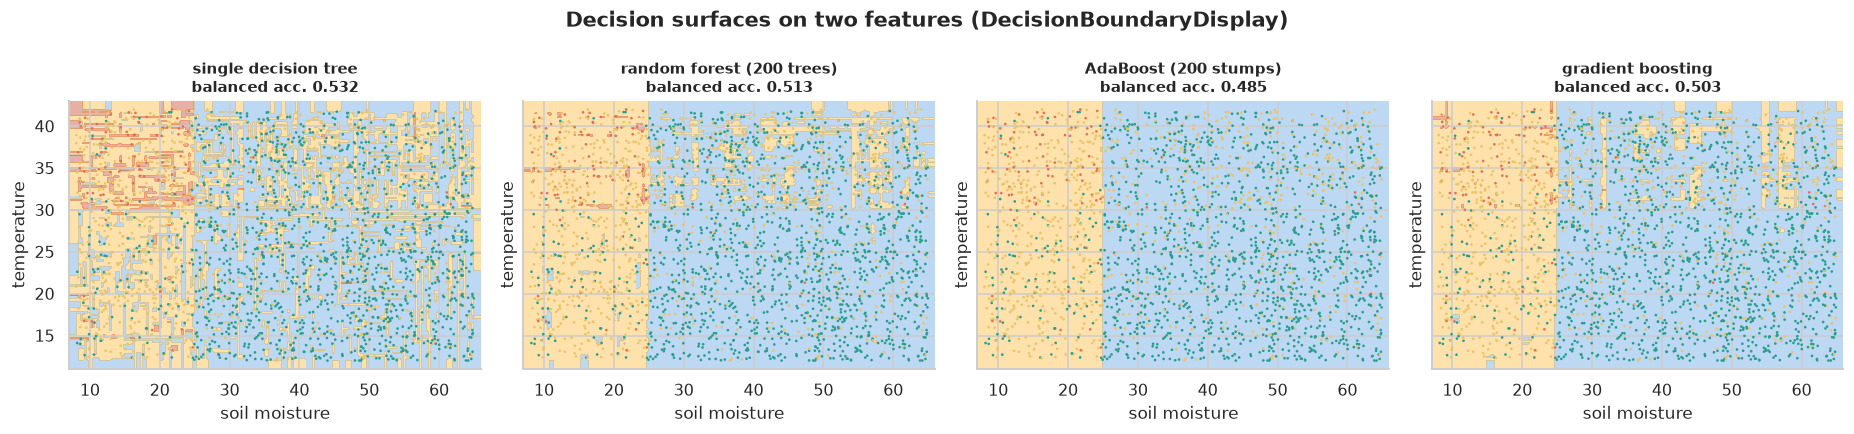

In [5]:
from sklearn.ensemble import AdaBoostClassifier, HistGradientBoostingClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

two = train[["Soil_Moisture", "Temperature_C"]].to_numpy()[:15000]
y2 = y_tr[:15000]
cmap = ListedColormap([plotting.CLASS_COLORS[c] for c in data.CLASSES])
models2 = {"single decision tree": DecisionTreeClassifier(random_state=0),
           "random forest (200 trees)": RandomForestClassifier(200, min_samples_leaf=5, n_jobs=-1, random_state=0),
           "AdaBoost (200 stumps)": AdaBoostClassifier(n_estimators=200, random_state=0),
           "gradient boosting": HistGradientBoostingClassifier(random_state=0)}
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for ax, (name, model) in zip(axes, models2.items()):
    model.fit(two, y2)
    DecisionBoundaryDisplay.from_estimator(model, two, response_method="predict", cmap=cmap, alpha=0.35, ax=ax, grid_resolution=200,
                                           xlabel="soil moisture", ylabel="temperature")
    ax.scatter(two[:2500, 0], two[:2500, 1], c=y2[:2500], cmap=cmap, s=3, edgecolor="none")
    ax.set_title(f"{name}\nbalanced acc. {balanced_accuracy_score(y_te, model.predict(test[['Soil_Moisture', 'Temperature_C']].to_numpy())):.3f}", fontsize=10)
fig.suptitle("Decision surfaces on two features (DecisionBoundaryDisplay)", fontweight="bold")
fig.tight_layout()
plotting.save("i05-boundaries")
plt.show()

The single tree's surface is speckled with tiny islands (variance); the forest smooths them out; the boosted models draw clean, deliberate steps.

## 4. Boosting ensembles

### AdaBoost (adaptive boosting)
Trains weak learners (usually stumps) in sequence. After each round, misclassified examples get **more weight**, so the next learner focuses on them; each learner's vote is weighted by its accuracy, αₘ = ln((1 − errₘ)/errₘ) + ln(K − 1) (the SAMME rule for K classes).

### Gradient boosting machines (GBM)
Each new tree fits the **negative gradient of the loss** (for squared error, the residuals) of the current ensemble, and is added with a small learning rate. It is gradient descent in function space. Watching both learn round by round:

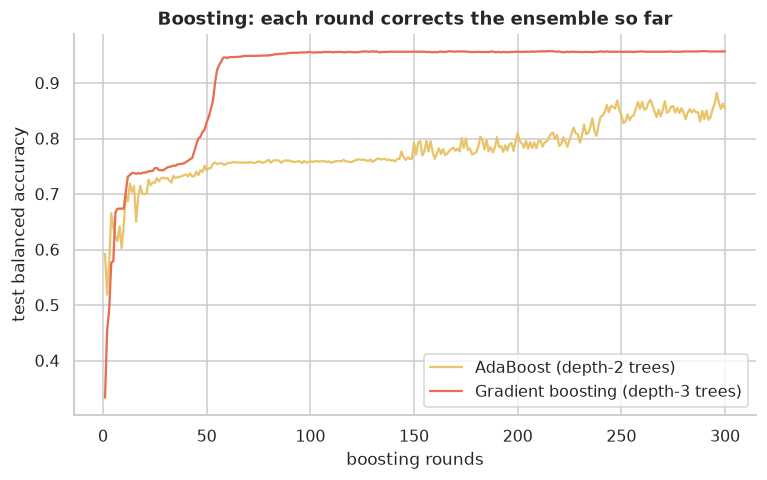

In [6]:
from sklearn.ensemble import GradientBoostingClassifier

ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=2), n_estimators=300, learning_rate=0.5, random_state=0).fit(A_tr[:20000], y_tr[:20000])
gbm = GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=3, subsample=0.8, random_state=0).fit(A_tr[:20000], y_tr[:20000])
fig, ax = plt.subplots()
for name, model, color in [("AdaBoost (depth-2 trees)", ada, "#e9c46a"), ("Gradient boosting (depth-3 trees)", gbm, "#e76f51")]:
    staged = [balanced_accuracy_score(y_te, p) for p in model.staged_predict(A_te)]
    ax.plot(range(1, len(staged) + 1), staged, label=name, color=color)
ax.set(xlabel="boosting rounds", ylabel="test balanced accuracy", title="Boosting: each round corrects the ensemble so far")
ax.legend()
plotting.save("i05-boosting")
plt.show()

## 5. Advanced boosting libraries

- **XGBoost:** gradient boosting with a second-order (Newton) step, L1/L2 penalties on the leaves, and a fast histogram algorithm.
- **LightGBM:** grows trees **leaf-wise** (always splits the leaf with the biggest gain) and uses histogram binning and gradient-based sampling: usually the fastest.
- **CatBoost:** built for categorical features: ordered target statistics instead of one-hot, and symmetric trees.

Same 40,000 training fields, same engineered features, native categorical handling in all three:

In [7]:
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from irrigate.features import DomainFeatures
from irrigate.submit import frame

dom = DomainFeatures().fit(train)
F_tr, F_te = frame(train, dom), frame(test, dom)
cat_cols = data.CATEGORICAL
libs = {
    "XGBoost": XGBClassifier(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, tree_method="hist", enable_categorical=True, random_state=0, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, n_jobs=-1, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=600, learning_rate=0.08, depth=6, one_hot_max_size=10, random_seed=0, verbose=0, thread_count=-1),
}
rows, lib_proba = [], {}
for name, model in libs.items():
    t0 = time.perf_counter()
    if name == "CatBoost":
        model.fit(F_tr.astype({c: str for c in cat_cols}), y_tr, cat_features=cat_cols)
        proba = model.predict_proba(F_te.astype({c: str for c in cat_cols}))
    else:
        model.fit(F_tr, y_tr)
        proba = model.predict_proba(F_te)
    lib_proba[name] = proba
    rows.append({"library": name, **evaluate.scores(y_te, proba.argmax(1), proba), "train seconds": time.perf_counter() - t0})
libs_table = pd.DataFrame(rows).set_index("library")
libs_table.round(4)

,balanced accuracy,accuracy,macro F1,High recall,High precision,"ROC AUC (macro, OvR)",train seconds
library,,,,,,,
XGBoost,0.9583,0.9832,0.9685,0.9085,0.9712,0.9965,4.7251
LightGBM,0.9580,0.9834,0.9679,0.9070,0.9680,0.9963,18.0898
CatBoost,0.9604,0.9835,0.9684,0.9145,0.9621,0.9965,3.7560


All three land within 0.003 of each other. With default settings on 40,000 fields they are no better than notebook 03's single tree (0.9595), which is an honest result: a good tree already captures this data's thresholds. The final model's gains come from what the libraries make possible at scale (all 630,000 rows, early stopping, blending) and from the decision weights.

One practical lesson from this project: CatBoost's default treatment of categorical columns (ordered target statistics, computed over many random permutations of the data) is powerful for columns with hundreds of values but very slow on a CPU. My first full-data run with the defaults had finished only one of its five folds after three and a half hours. Every categorical column here has at most 6 values, so `one_hot_max_size=10` tells CatBoost to use plain one-hot splits instead, and 100 trees on 40,000 fields then take about a second.

## 6. Ensemble regression models
The same ensembles work for regression: averaging trees (random forest) or boosting on residuals. On the crop-yield data from notebook 04, cross-validated by country:

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from lightgbm import LGBMRegressor

yd = data.yields()
yd["log_pesticides"] = np.log1p(yd["pesticides_t"])
Xy, yy = yd[["rain_mm", "temp_c", "log_pesticides", "year", "crop"]], np.log(yd["yield_t_ha"])
ct = ColumnTransformer([("num", "passthrough", ["rain_mm", "temp_c", "log_pesticides", "year"]), ("crop", OneHotEncoder(sparse_output=False), ["crop"])])
regs = {
    "Ridge (single linear model)": Ridge(1.0),
    "Random forest": RandomForestRegressor(300, min_samples_leaf=3, n_jobs=-1, random_state=0),
    "Gradient boosting": GradientBoostingRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, random_state=0),
    "LightGBM": LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, random_state=0, verbose=-1),
}
regs["Voting (RF + GBM + LightGBM)"] = VotingRegressor([(k, v) for k, v in regs.items() if k != "Ridge (single linear model)"])
pd.Series({name: cross_val_score(make_pipeline(ct, m), Xy, yy, groups=yd["country"], cv=GroupKFold(5), scoring="r2").mean() for name, m in regs.items()},
          name="CV R², unseen countries").round(4).to_frame()

,"CV R², unseen countries"
Ridge (single linear model),0.6731
Random forest,0.6303
Gradient boosting,0.6578
LightGBM,0.6471
Voting (RF + GBM + LightGBM),0.6615


The ensembles don't change the story of notebook 04: on countries they have never seen, the single Ridge model (0.673) still beats every tree ensemble, and the voting regressor (0.662) lands between its members. Ensembles reduce variance, but they can't fix a model that can't extrapolate.

## 7. Model evaluation and hyperparameter tuning

### Cross-validation strategies
- **k-fold:** k equal parts, each used once as validation.
- **Stratified k-fold:** keeps the class proportions in every fold. Essential here: plain k-fold lets the share of High drift between folds.
- **Group k-fold:** keeps whole groups (countries in notebook 04) together, so the model is tested on groups it never saw.
- **Time-series split:** train on the past, test on the future (notebook 04).
- **Repeated** versions rerun with different shuffles to reduce the noise in the estimate.

In [9]:
from sklearn.model_selection import KFold

small = data.sample(3000, seed=6)
ys = small[data.TARGET].cat.codes.to_numpy()
shares = {}
for name, splitter in [("KFold", KFold(10, shuffle=True, random_state=0)), ("StratifiedKFold", StratifiedKFold(10, shuffle=True, random_state=0))]:
    shares[name] = [np.mean(ys[va] == 2) for _, va in splitter.split(small, ys)]
pd.DataFrame(shares, index=[f"fold {i + 1}" for i in range(10)]).T.mul(100).round(2).assign(spread=lambda d: d.max(axis=1) - d.min(axis=1))

,fold 1,fold 2,fold 3,fold 4,fold 5,fold 6,fold 7,fold 8,fold 9,fold 10,spread
KFold,2.33,2.00,2.67,2.33,5.00,2.00,3.67,3.67,4.67,5.00,3.0
StratifiedKFold,3.33,3.33,3.33,3.33,3.33,3.33,3.33,3.33,3.33,3.33,0.0


Above: % of High fields in each validation fold of a 3,000-row sample. Plain k-fold lets it swing between folds; stratified k-fold keeps every fold at the true share.

### Pipelines
Every model in this project is a `Pipeline` (pre-processing → features → model), so cross-validation refits *everything* on each training fold. That is the leakage protection from notebook 01, built in. A pipeline is also one object to tune, save and deploy:

In [10]:
pipe = preprocess.pipeline(LGBMClassifier(n_estimators=300, verbose=-1, random_state=0), scale=None, engineered=True)
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('columns', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nominal', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{

### Hyperparameter tuning techniques
Grid search tries every combination; random search samples combinations (better when only a few parameters matter); successive halving starts many candidates on a little data and only promotes the best to more data. All three on the same LightGBM pipeline and the same budget of candidates:

In [11]:
from scipy.stats import loguniform, randint
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import GridSearchCV, HalvingRandomSearchCV, RandomizedSearchCV

tune_df = data.sample(20_000, seed=7)
y_tune = tune_df[data.TARGET].cat.codes.to_numpy()
cv3 = StratifiedKFold(3, shuffle=True, random_state=0)
grid = {"model__num_leaves": [15, 31, 63], "model__learning_rate": [0.03, 0.1, 0.3], "model__min_child_samples": [10, 40]}
dists = {"model__num_leaves": randint(8, 128), "model__learning_rate": loguniform(0.01, 0.3), "model__min_child_samples": randint(5, 100)}
searches = {
    "grid search (18 combinations)": GridSearchCV(pipe, grid, cv=cv3, scoring="balanced_accuracy", n_jobs=1),
    "random search (18 samples)": RandomizedSearchCV(pipe, dists, n_iter=18, cv=cv3, scoring="balanced_accuracy", random_state=0, n_jobs=1),
    "successive halving (54 candidates)": HalvingRandomSearchCV(pipe, dists, n_candidates=54, factor=3, resource="n_samples", min_resources=2000,
                                                                cv=cv3, scoring="balanced_accuracy", random_state=0, n_jobs=1),
}
rows = []
for name, search in searches.items():
    t0 = time.perf_counter()
    search.fit(tune_df, y_tune)
    rows.append({"method": name, "best CV balanced accuracy": search.best_score_, "seconds": time.perf_counter() - t0,
                 "best parameters": {k.replace("model__", ""): (round(v, 3) if isinstance(v, float) else v) for k, v in search.best_params_.items()}})
pd.DataFrame(rows).set_index("method").round(4)

,best CV balanced accuracy,seconds,best parameters
method,,,
grid search (18 combinations),0.9520,236.2378,"{'learning_rate': 0.3, 'min_child_samples': 10..."
random search (18 samples),0.9518,380.2725,"{'learning_rate': 0.208, 'min_child_samples': ..."
successive halving (54 candidates),0.9474,780.3176,"{'learning_rate': 0.229, 'min_child_samples': ..."


Here plain grid search found the best setting (0.9520) and was also the fastest; random search came close. Successive halving was the slowest and scored lowest, because its early rounds judge candidates on only 2,000 fields, too few to rank LightGBM settings reliably. Halving pays off with much larger search spaces and data.

### Summary table: tuning methods

| Method | Searches | Good for | Cost |
|---|---|---|---|
| Grid search | every combination of listed values | 2–3 parameters, small grids | grows exponentially with parameters |
| Random search | random draws from distributions | many parameters, few that matter | fixed budget you choose |
| Successive halving | many candidates, cheap first rounds | large search spaces | most candidates only see little data |
| Bayesian optimisation (e.g. Optuna) | a model of score vs parameters | expensive models | sequential, needs a library |

## 8. The final submission

Everything above, at full scale: `python -m irrigate.submit` trains LightGBM, XGBoost and CatBoost on all 630,000 fields with 5-fold stratified cross-validation and early stopping, averages their probabilities (soft voting), and then tunes the **decision weights** for balanced accuracy (`irrigate.decision`, the class-imbalance fix from notebook 01). The CatBoost model uses the one-hot setting from section 5. The weights are tuned on four folds' out-of-fold predictions and checked on the fifth before being trusted. The same script also re-scores my original April approach (one-hot features, XGBoost with 200 trees, argmax) with the same folds, for a like-for-like comparison.

The run takes a while, so its outputs (`submissions/report.json` and the out-of-fold predictions) are loaded here.

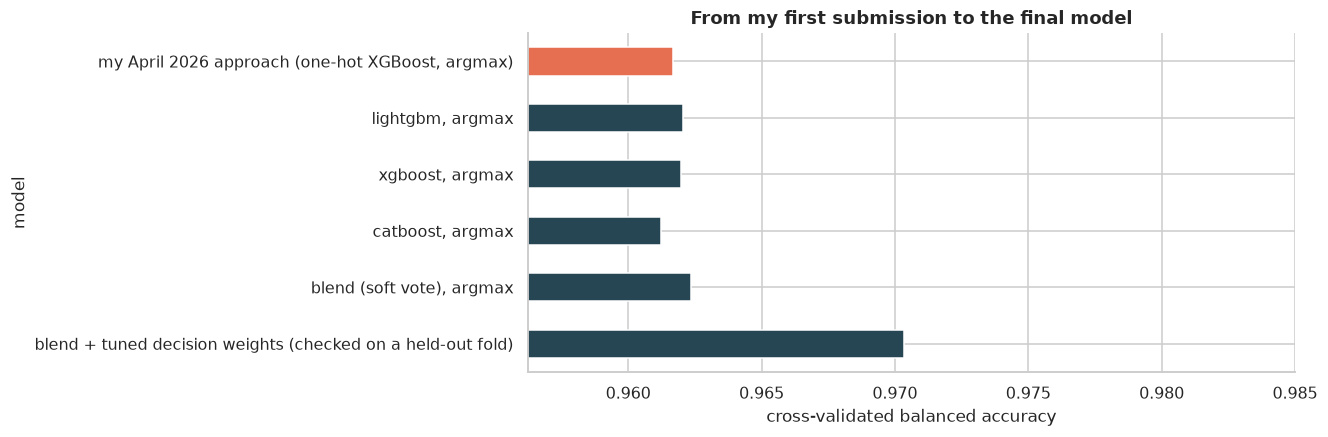

decision weights (Low, Medium, High): [1.0, 0.518, 8.437]
held-out fold: argmax 0.96217 -> tuned weights 0.97033


,CV balanced accuracy
model,
"my April 2026 approach (one-hot XGBoost, argmax)",0.96169
"lightgbm, argmax",0.96206
"xgboost, argmax",0.96199
"catboost, argmax",0.96124
"blend (soft vote), argmax",0.96236
blend + tuned decision weights (checked on a held-out fold),0.97033


In [12]:
from pathlib import Path
out = Path(irrigate.__file__).resolve().parents[2] / "submissions"
report = json.loads((out / "report.json").read_text())
baseline = json.loads((out / "baseline.json").read_text())
rows = [{"model": "my April 2026 approach (one-hot XGBoost, argmax)", "CV balanced accuracy": baseline["CV balanced accuracy, argmax"]}]
final_models = report["blend"]["models"]
for name in final_models:
    rows.append({"model": f"{name}, argmax", "CV balanced accuracy": report[name]["CV balanced accuracy, argmax"]})
rows.append({"model": "blend (soft vote), argmax", "CV balanced accuracy": report["blend"]["CV balanced accuracy, argmax"]})
rows.append({"model": "blend + tuned decision weights (checked on a held-out fold)", "CV balanced accuracy": report["blend"]["held-out fold, weights tuned on the other folds"]})
final = pd.DataFrame(rows).set_index("model")
ax = final["CV balanced accuracy"].iloc[::-1].plot.barh(color=[plotting.ACCENT] * (len(final) - 1) + ["#e76f51"], figsize=(9, 4))
ax.set(xlim=(final["CV balanced accuracy"].min() - 0.005, 0.985), xlabel="cross-validated balanced accuracy", title="From my first submission to the final model")
plotting.save("i05-final")
plt.show()
print("decision weights (Low, Medium, High):", report["blend"]["weights (Low, Medium, High)"])
print("held-out fold: argmax", round(report["blend"]["held-out fold, argmax"], 5), "-> tuned weights", round(report["blend"]["held-out fold, weights tuned on the other folds"], 5))
final.round(5)

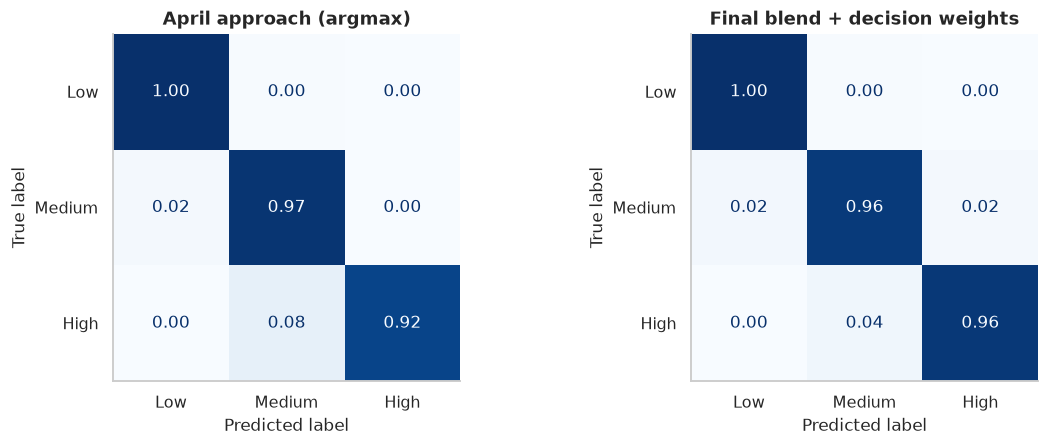

In [13]:
y_all = data.load()[data.TARGET].cat.codes.to_numpy()
blend_oof = np.mean([np.load(out / f"oof_{m}.npy") for m in final_models], axis=0)
w = np.array(report["blend"]["weights (Low, Medium, High)"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
evaluate.confusion(y_all, np.load(out / "oof_baseline.npy").argmax(1), ax=axes[0], title="April approach (argmax)")
evaluate.confusion(y_all, decision.decide(blend_oof, w), ax=axes[1], title="Final blend + decision weights")
fig.tight_layout()
plotting.save("i05-final-confusion")
plt.show()

The difference is almost all in the High row. The April model predicted 8.4% of truly High fields as Medium; the final model 3.8%, so High recall rises from 0.916 to 0.962. The price is that Medium fields called High rise from 0.3% to 2.0%, which is exactly the trade balanced accuracy rewards.

## 9. Kaggle's verdict

The real test is Kaggle's hidden labels. The submission files were uploaded on 24 October 2026 as late submissions (the competition closed on 30 April, so they are scored but not ranked). All three submissions as Kaggle reports them:

| Submission | Public score | Private score |
|---|---|---|
| April 2026: one-hot XGBoost, argmax | 0.96021 | 0.96077 |
| October 2026: LightGBM + XGBoost, decision weights | 0.96849 | 0.97068 |
| October 2026: LightGBM + XGBoost + CatBoost, decision weights (final) | **0.96985** | **0.97126** |

The private score, the one the final ranking uses, rose by 0.0105. The held-out fold had predicted +0.0086, so the cross-validation was honest and, if anything, slightly cautious. On the public leaderboard, 0.96985 would sit at about rank 1,185 of 4,316 (the top 28%), where my April score sits at about 2,659. Most of the gain comes from two things this course is about: features that encode what the data analysis found, and a decision rule that matches the metric.

| Syllabus topic | Where |
|---|---|
| Introduction, bias–variance in ensembles | 1 |
| Majority voting: hard and soft, formulation | 2 |
| Bagging, random forest | 3 |
| AdaBoost, gradient boosting | 4 |
| XGBoost, LightGBM, CatBoost | 5 |
| Ensemble regression | 6 |
| Cross-validation strategies, pipelines, tuning methods | 7 |
| Final model and submission | 8–9 |